# Tendencia de clustering sobre la **forma** de la trayectoria (Hopkins y VAT) · Perfiles de votantes

**Proyecto:** Hackathon INE 2026 · Reto 1 · Perfiles ciudadanos de participación.
Continuación de `tendencia_clustering.ipynb`.

## Pregunta que responde
El notebook anterior usó las 6 tasas de participación (el **nivel**) y no encontró grupos: todo era un gradiente por edad, que en la práctica es "participa más o menos". Aquí se quita el nivel y se mira solo la **forma** de la trayectoria: ¿cuánto sube la unidad en elecciones presidenciales frente a intermedias y cómo cambia entre elecciones del mismo tipo? Si hay perfiles que se distinguen por la forma, Hopkins y VAT deberían mostrarlos.

## Dos representaciones de la forma
- **`forma`**: las 6 tasas menos el promedio de la propia fila (se pierde el nivel), reducidas a 5 componentes con PCA. Las 6 tasas centradas solo tienen 5 grados de libertad, por eso 5 componentes y no 6.
- **`ciclo`**: 3 variables interpretables:
  - `brecha_ciclo` = promedio de presidenciales (2012, 2018, 2024) − promedio de intermedias (2009, 2015, 2021);
  - `tend_pres` = tasa 2024 − tasa 2012;
  - `tend_inter` = tasa 2021 − tasa 2009.

Cada una se prueba también **sin efecto entidad** (a cada tasa se le resta la media de su entidad antes de calcular la forma).

## Alcance
Entra: construir las variables de forma, medir la tendencia y comparar con el nulo. **No entra**: el clustering ni la elección de k. Misma unidad, filtros de calidad, semilla (42) y veredicto que el notebook anterior.

## Índice
1. Entorno · 2. Carga y tabla · 3. Variables de forma · 4. ¿La forma es independiente del nivel y de la edad? · 5. Hopkins · 6. Imágenes VAT · 7. ¿Qué ordena la forma? · 8. Autopruebas · 9. Conclusiones

## 1. Entorno

In [1]:
import platform
from pathlib import Path
import numpy as np, pandas as pd, scipy, sklearn, matplotlib
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from scipy.spatial.distance import pdist, squareform
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import normalized_mutual_info_score as nmi

SEED = 42
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/processed').exists())
DATA = ROOT / 'data/processed/civia_dataset_maestro_municipal_2009_2024_con_region.csv'
OUT = ROOT / 'reports/local/tendencia_forma'
OUT.mkdir(parents=True, exist_ok=True)

YEARS = [2009, 2012, 2015, 2018, 2021, 2024]
FEATURES = [f'part_{y}' for y in YEARS]
PRES = ['part_2012', 'part_2018', 'part_2024']
INTER = ['part_2009', 'part_2015', 'part_2021']
REGIONS = ['norte', 'centro', 'sur']
COUNTS = ['lista_nominal', 'si_votaron', 'no_votaron', 'no_especificados']
MIN_ESP, MAX_NS = 100, 20     # filtro de calidad (igual que el notebook anterior)
REPS = 50                     # repeticiones de Hopkins

print(f'Python {platform.python_version()} · numpy {np.__version__} · pandas {pd.__version__} · '
      f'scipy {scipy.__version__} · scikit-learn {sklearn.__version__} · matplotlib {matplotlib.__version__}')

Python 3.14.8 · numpy 2.5.4 · pandas 3.1.0 · scipy 1.18.1 · scikit-learn 1.9.1 · matplotlib 3.11.2


## 2. Carga y tabla
Mismo procedimiento que el notebook anterior: se suman los conteos municipales por entidad × sexo × edad × sección × año, la tasa se **recalcula** desde las sumas y se aplican los filtros (6 tasas disponibles, al menos 100 registros especificados y NS ≤ 20 % en cada elección). No binario queda fuera.

In [2]:
d = pd.read_csv(DATA, encoding='utf-8-sig')
assert (d.lista_nominal == d.si_votaron + d.no_votaron + d.no_especificados).all()
d = d[d.sexo != 'No binario']

KEY = ['region', 'entidad_clave', 'sexo', 'grupo_edad', 'tipo_seccion_codigo']
a = d.groupby([*KEY, 'anio'], observed=True)[COUNTS].sum()
a['esp'] = a.si_votaron + a.no_votaron
a['part'] = a.si_votaron / a.esp.where(a.esp > 0)
a['ns_pct'] = 100 * a.no_especificados / a.lista_nominal.where(a.lista_nominal > 0)
wide = {k: a[k].unstack('anio').reindex(columns=YEARS) for k in ['part', 'esp', 'ns_pct']}
T = wide['part'].copy()
T.columns = FEATURES
ok = T.notna().all(axis=1) & wide['esp'].ge(MIN_ESP).all(axis=1) & wide['ns_pct'].le(MAX_NS).all(axis=1)
perdidas = pd.DataFrame({'antes': T.groupby('region').size(), 'despues': T[ok].groupby('region').size()}).reindex(REGIONS)
perdidas['perdidas_%'] = (100 * (1 - perdidas.despues / perdidas.antes)).round(1)
T = T[ok]
cases = {r: T.xs(r, level='region', drop_level=False) for r in REGIONS}   # análisis A
cases['conjunto'] = T                                                      # análisis B (control)
perdidas

,antes,despues,perdidas_%
region,,,
norte,576,521,9.5
centro,576,560,2.8
sur,384,377,1.8


## 3. Variables de forma
`formas(frame)` devuelve las dos representaciones. Con `centrar_entidad=True` se resta antes la media de la entidad a cada tasa.

Un detalle de método: las 6 tasas centradas por fila viven en un subespacio de 5 dimensiones. Si se dejaran como 6 columnas, Hopkins generaría puntos uniformes fuera de ese subespacio y saldría alto por construcción. Por eso `forma` pasa por PCA a 5 componentes.

In [3]:
def formas(frame, centrar_entidad=False):
    """Dos representaciones de la forma de la trayectoria, sin el nivel de participación.

    frame: tabla ancha con FEATURES. centrar_entidad: resta primero la media de la entidad a cada tasa.
    Devuelve dict {'forma': (n,5) PCA, 'ciclo': (n,3) estandarizada} y el DataFrame de las 3 variables de ciclo.
    """
    raw = frame[FEATURES]
    if centrar_entidad:
        raw = raw - raw.groupby(frame.index.get_level_values('entidad_clave')).transform('mean')
    cic = pd.DataFrame({'brecha_ciclo': raw[PRES].mean(axis=1) - raw[INTER].mean(axis=1),
                        'tend_pres': raw.part_2024 - raw.part_2012,
                        'tend_inter': raw.part_2021 - raw.part_2009}, index=frame.index)
    centrada = raw.sub(raw.mean(axis=1), axis=0)
    return {'forma': PCA(5, random_state=SEED).fit_transform(centrada),
            'ciclo': StandardScaler().fit_transform(cic)}, cic


def nulos(X, seed=SEED):
    """Dos referencias sin grupos: gaussiana con igual media/covarianza y columnas permutadas."""
    rng = np.random.default_rng(seed)
    return {'gauss': rng.multivariate_normal(X.mean(0), np.cov(X.T), len(X)),
            'perm': np.column_stack([rng.permutation(c) for c in X.T])}


def veredicto(h, delta):
    """Misma regla heurística del notebook anterior (umbrales exploratorios)."""
    if h > 0.75 and delta > 0.10: return 'clara'
    if h > 0.60 and delta > 0.05: return 'moderada'
    return 'sin evidencia'


def hopkins(X, m=None, reps=REPS, seed=SEED):
    """Estadístico de Hopkins: devuelve (media, desviación estándar) en `reps` repeticiones.

    X: matriz (n, d). m: tamaño de muestra (por defecto 10 % de n, mínimo 10).
    """
    rng = np.random.default_rng(seed)
    n, dim = X.shape
    m = m or max(10, n // 10)
    tree = cKDTree(X)
    lo, hi = X.min(0), X.max(0)
    hs = []
    for _ in range(reps):
        w = tree.query(X[rng.choice(n, m, replace=False)], k=2)[0][:, 1]   # vecino más cercano distinto de sí mismo
        u = tree.query(rng.uniform(lo, hi, (m, dim)), k=1)[0]
        hs.append(u.sum() / (u.sum() + w.sum()))
    return float(np.mean(hs)), float(np.std(hs))


def vat(X):
    """Matriz de distancias reordenada (VAT): devuelve (matriz n×n, orden de filas)."""
    D = squareform(pdist(X))
    n = len(D)
    first = int(np.unravel_index(D.argmax(), D.shape)[0])
    order, rest = [first], np.ones(n, bool)
    rest[first] = False
    near = D[first].copy()
    for _ in range(n - 1):
        j = int(np.argmin(np.where(rest, near, np.inf)))
        order.append(j)
        rest[j] = False
        near = np.minimum(near, D[j])
    return D[np.ix_(order, order)], np.array(order)


cic_all = formas(T)[1]
cic_all.describe().round(3)

,brecha_ciclo,tend_pres,tend_inter
count,1458.000,1458.000,1458.000
mean,0.108,-0.019,0.087
std,0.053,0.061,0.099
min,-0.012,-0.206,-0.168
25%,0.070,-0.062,0.013
50%,0.110,-0.021,0.098
75%,0.145,0.029,0.149
max,0.278,0.156,0.363


## 4. ¿La forma es independiente del nivel y de la edad?
Antes de medir tendencia hay que comprobar que quitar el nivel funcionó. Se calcula la correlación de cada variable de forma con el **nivel** (promedio de las 6 tasas de la fila) y, como contraste, el promedio de cada variable por grupo de edad. Una correlación alta con el nivel indicaría que la forma sigue siendo "participa más o menos".

In [4]:
nivel = T[FEATURES].mean(axis=1)
Xf, cic = formas(T)
corr = pd.concat([cic.corrwith(nivel).rename('corr con nivel'),
                  pd.Series({f'PC{i+1} (forma)': np.corrcoef(Xf['forma'][:, i], nivel)[0, 1] for i in range(5)}, name='corr con nivel')])
display(corr.round(3).to_frame())
print('Promedio de las variables de ciclo por grupo de edad (puntos de participación):')
(100 * cic.groupby(T.index.get_level_values('grupo_edad')).mean()).round(1)

,corr con nivel
brecha_ciclo,-0.171
tend_pres,0.036
tend_inter,-0.017
PC1 (forma),0.098
PC2 (forma),0.126
PC3 (forma),0.097
PC4 (forma),-0.034
PC5 (forma),-0.058


Promedio de las variables de ciclo por grupo de edad (puntos de participación):


,brecha_ciclo,tend_pres,tend_inter
grupo_edad,,,
18-24,11.3,-6.0,7.4
25-34,11.8,-4.2,6.6
35-44,11.9,-6.1,7.2
45-54,11.1,-4.9,6.8
55-64,10.4,-3.0,7.4
65-74,9.8,2.4,9.9
75-84,10.2,3.6,11.0
85+,10.2,3.2,13.0


## 5. Hopkins
Cada fila es un caso × representación. `delta = H_real − H_gauss`. Misma regla de veredicto que el notebook anterior.

In [5]:
rows, X_cases = [], {}
for case, frame in cases.items():
    for ent_flag, ent_name in ((False, ''), (True, ' sin ent.')):
        reps, _ = formas(frame, centrar_entidad=ent_flag)
        for var, X in reps.items():
            X_cases[(case, var + ent_name)] = X
            h, sd = hopkins(X)
            nul = nulos(X)
            hg, hp = hopkins(nul['gauss'])[0], hopkins(nul['perm'])[0]
            rows.append({'caso': case, 'variante': var + ent_name, 'n': len(X), 'H_real': round(h, 3), 'sd': round(sd, 3),
                         'H_gauss': round(hg, 3), 'H_perm': round(hp, 3), 'delta': round(h - hg, 3), 'veredicto': veredicto(h, h - hg)})
resumen = pd.DataFrame(rows)
resumen.to_csv(OUT / 'resumen_hopkins_forma.csv', index=False)
resumen

,caso,variante,n,H_real,sd,H_gauss,H_perm,delta,veredicto
0,norte,forma,521,0.758,0.014,0.669,0.665,0.089,moderada
1,norte,ciclo,521,0.822,0.015,0.810,0.676,0.013,sin evidencia
2,norte,forma sin ent.,521,0.716,0.013,0.670,0.678,0.046,sin evidencia
3,norte,ciclo sin ent.,521,0.793,0.022,0.798,0.721,-0.005,sin evidencia
4,centro,forma,560,0.769,0.010,0.670,0.649,0.099,moderada
5,centro,ciclo,560,0.793,0.020,0.809,0.620,-0.016,sin evidencia
6,centro,forma sin ent.,560,0.717,0.014,0.671,0.677,0.046,sin evidencia
7,centro,ciclo sin ent.,560,0.785,0.021,0.795,0.687,-0.010,sin evidencia
8,sur,forma,377,0.748,0.014,0.649,0.610,0.099,moderada
9,sur,ciclo,377,0.766,0.023,0.766,0.637,-0.000,sin evidencia


## 6. Imágenes VAT
Por caso, dos filas (`forma` y `ciclo`) y tres columnas: datos reales, nulo gaussiano con la misma covarianza y datos sin efecto entidad. **Oscuro = cercano.** Bloques cuadrados oscuros en la diagonal sugieren grupos; si el panel real se parece al nulo, no hay grupos.

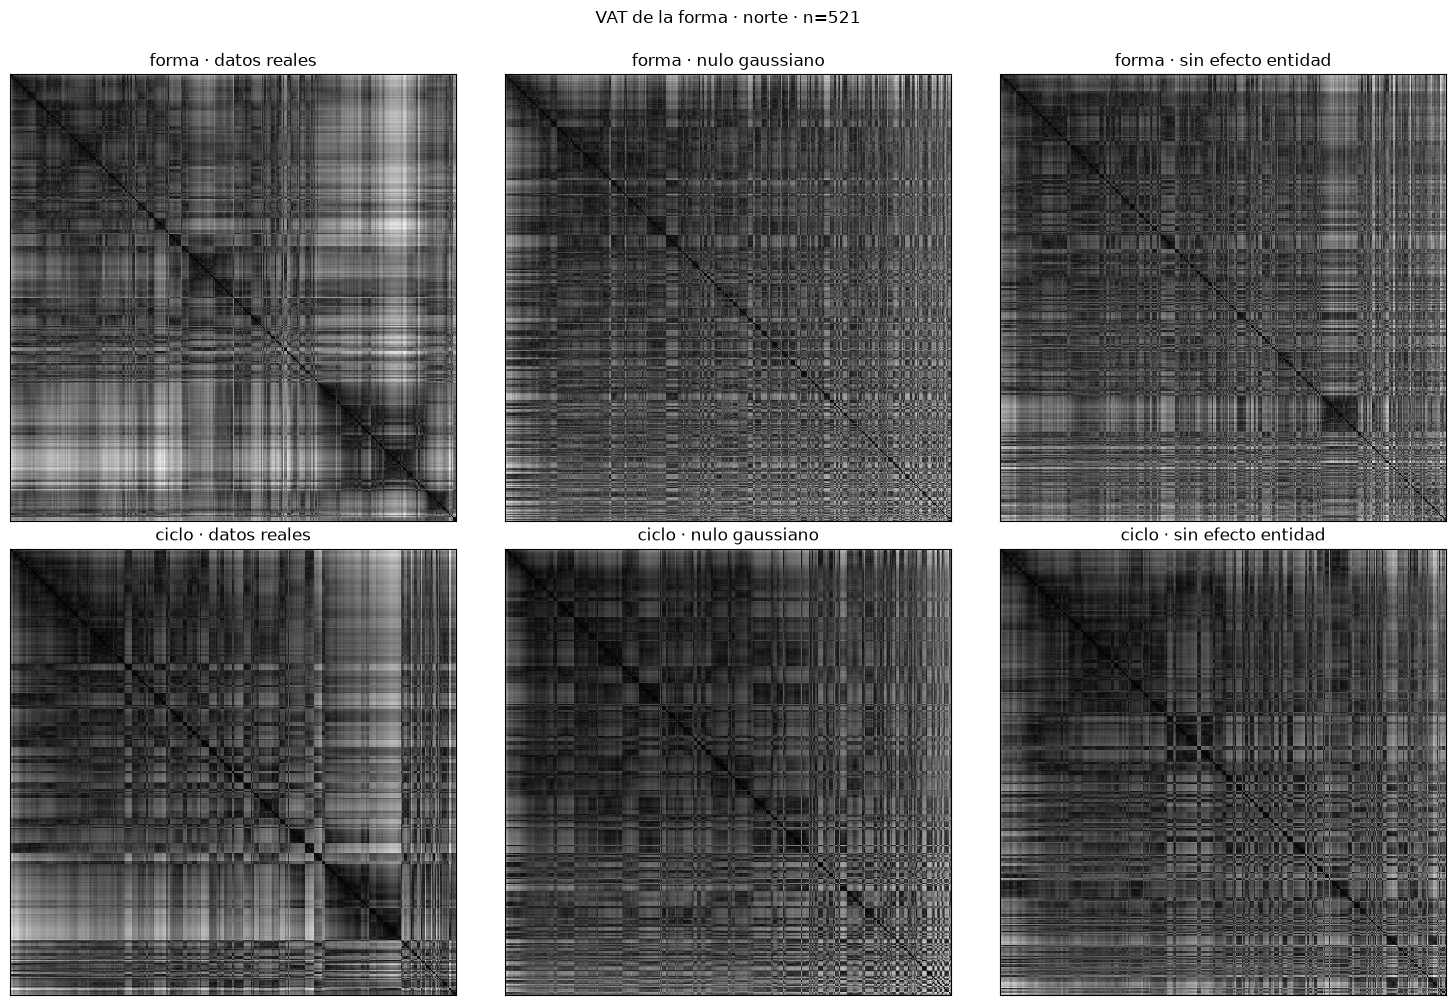

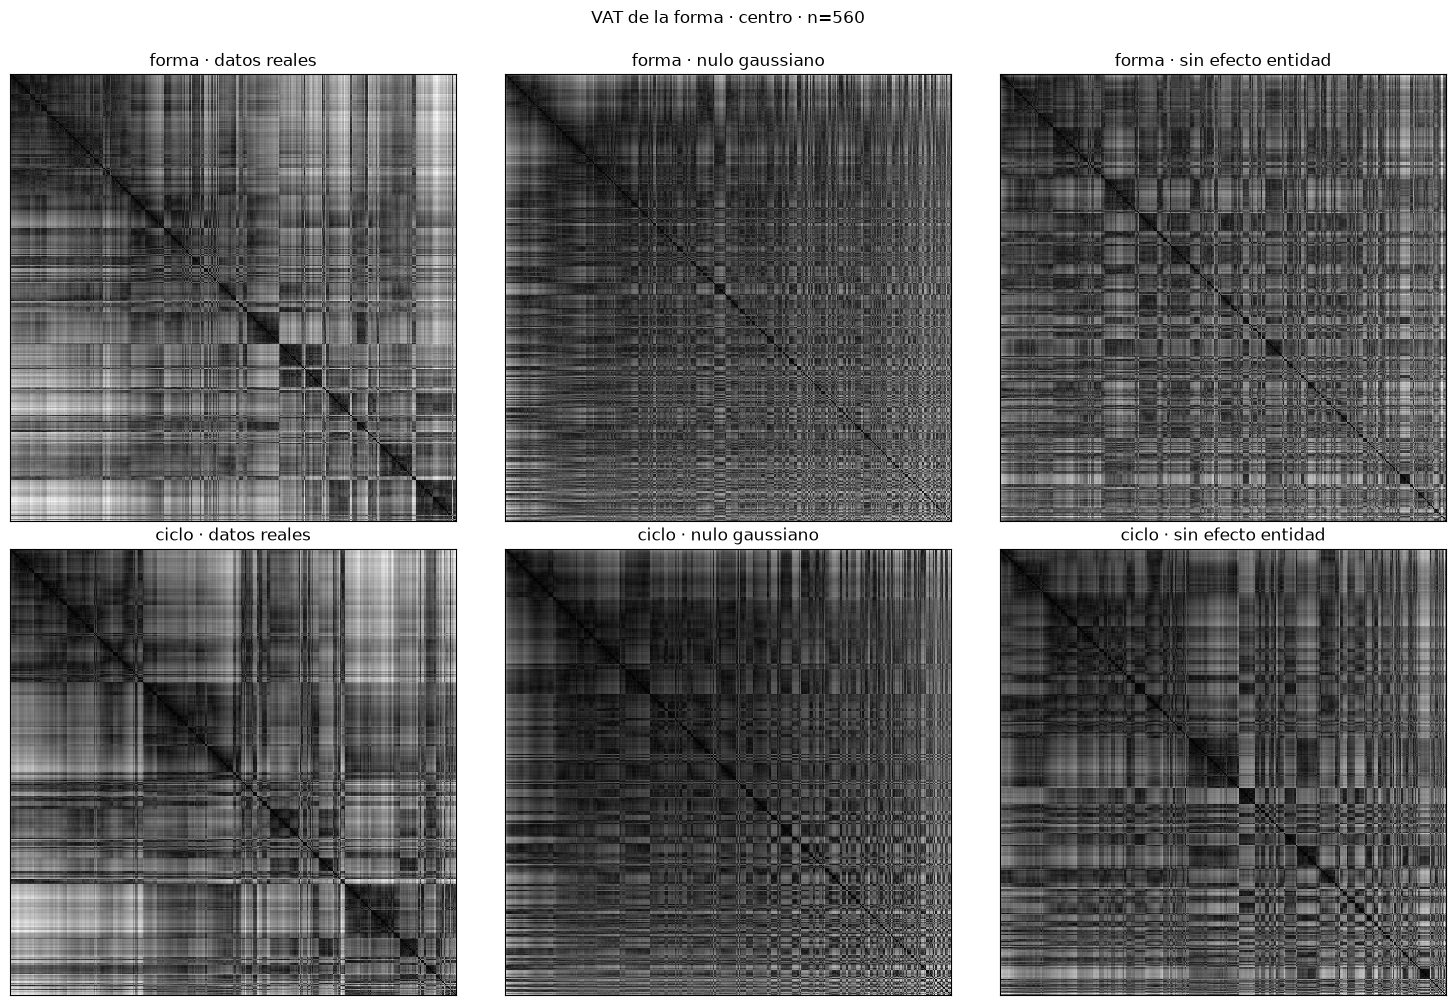

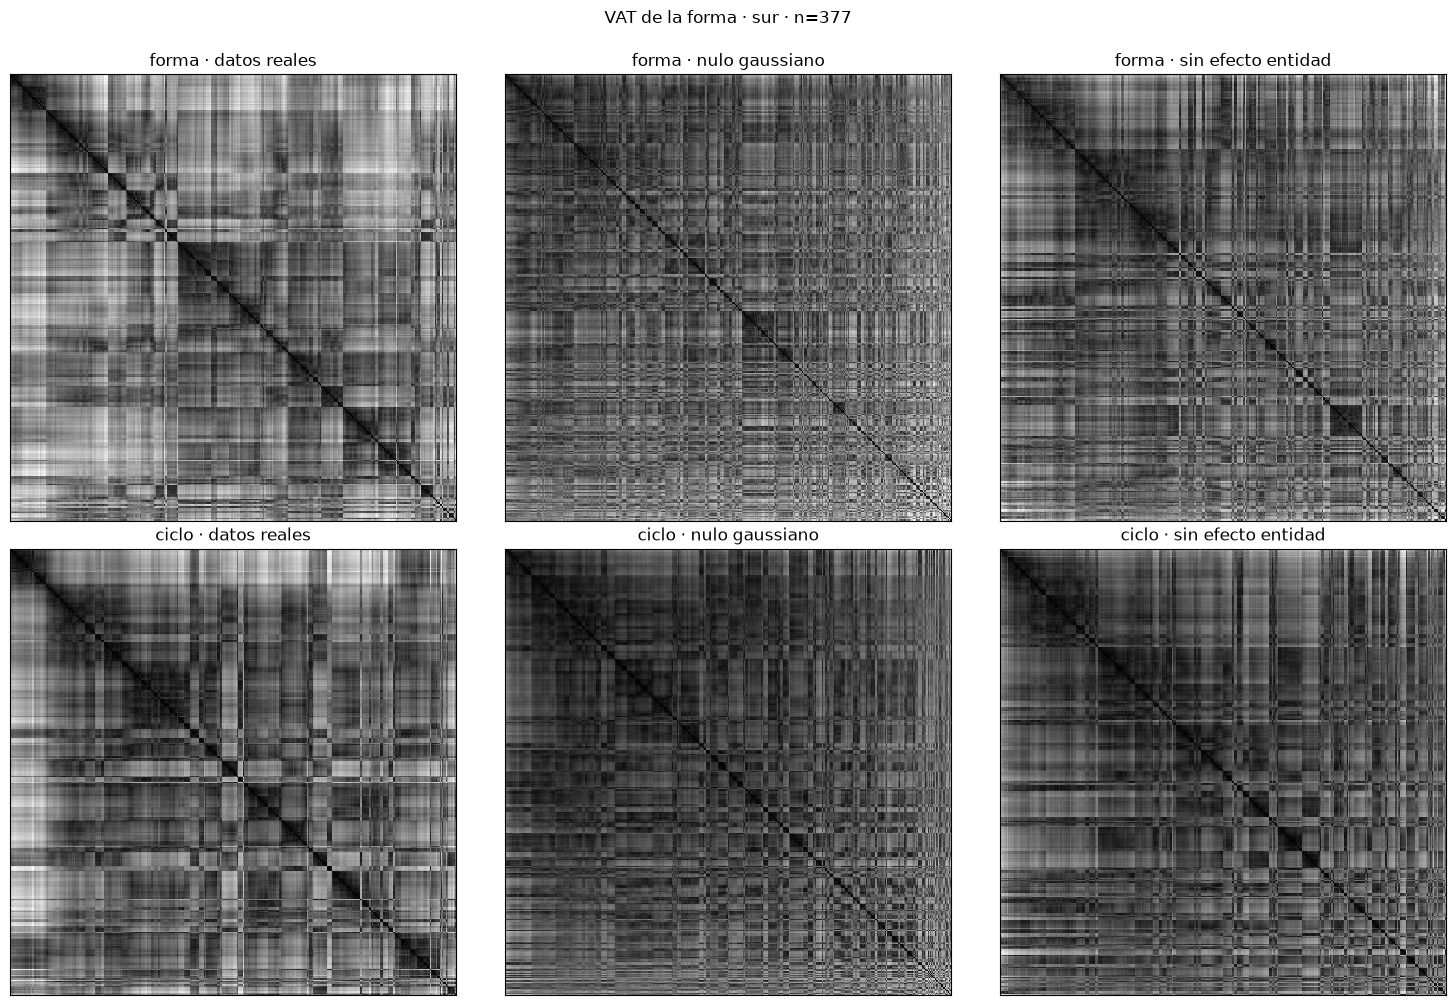

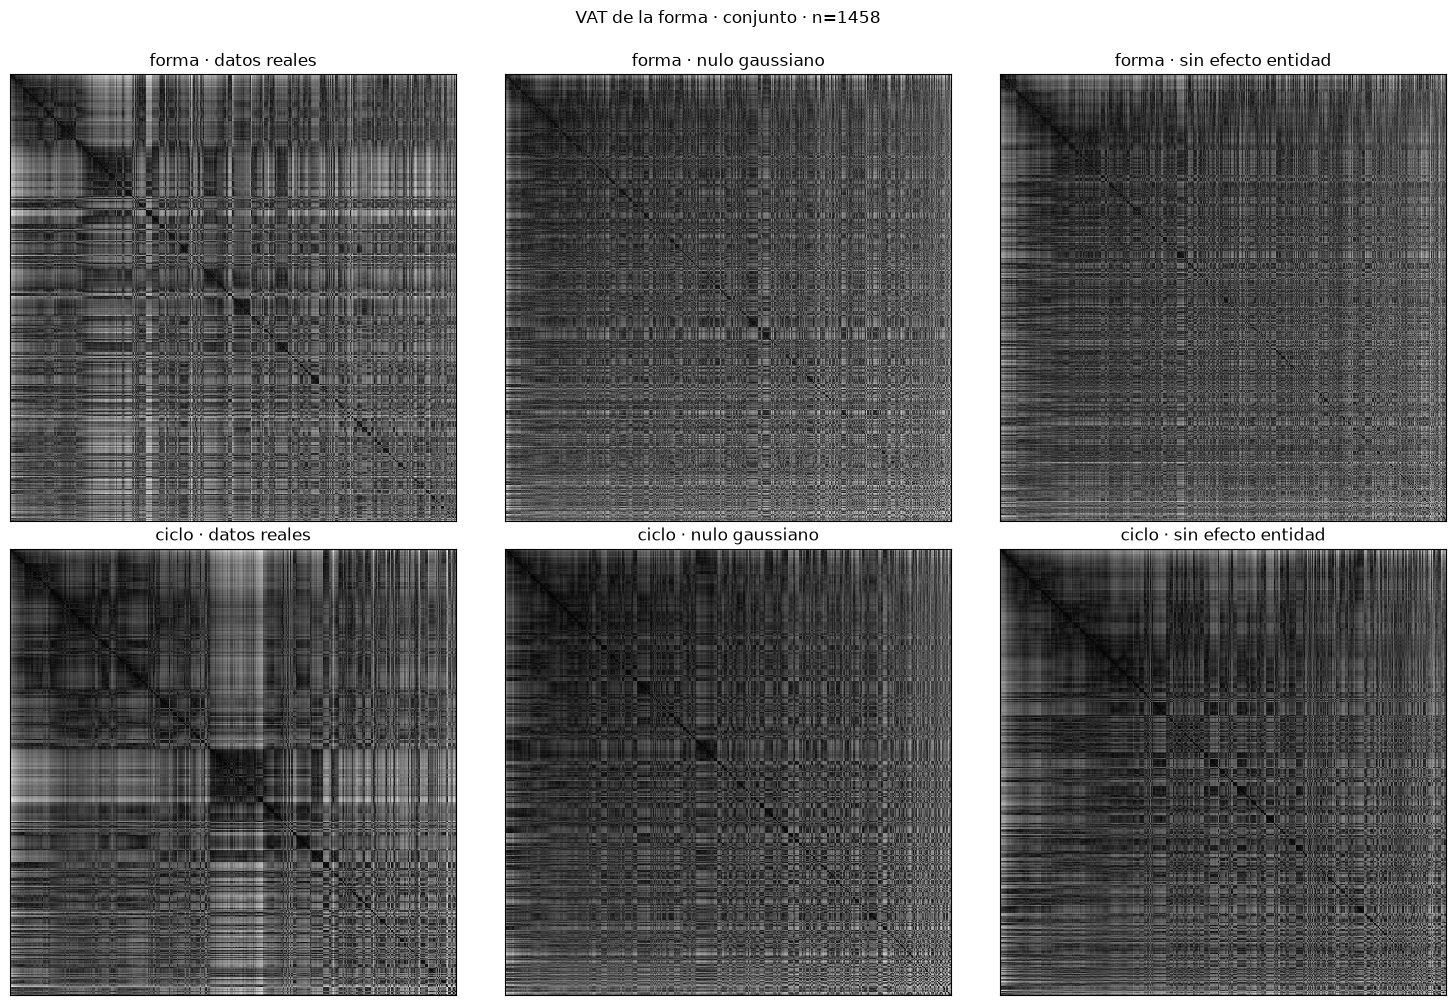

In [6]:
for case, frame in cases.items():
    fig, axs = plt.subplots(2, 3, figsize=(15, 10))
    for r, var in enumerate(('forma', 'ciclo')):
        X = X_cases[(case, var)]
        paneles = [(X, f'{var} · datos reales'), (nulos(X)['gauss'], f'{var} · nulo gaussiano'), (X_cases[(case, var + ' sin ent.')], f'{var} · sin efecto entidad')]
        for ax, (Z, titulo) in zip(axs[r], paneles):
            ax.imshow(vat(Z)[0], cmap='gray', interpolation='nearest')
            ax.set(title=titulo, xticks=[], yticks=[])
    fig.suptitle(f'VAT de la forma · {case} · n={len(X)}', y=1.0)
    fig.tight_layout()
    fig.savefig(OUT / f'vat_forma_{case}.png', dpi=150, bbox_inches='tight')
    plt.show()

## 7. ¿Qué ordena la forma?
Diagnóstico, **no** es el clustering final: se corta cada caso en 2, 3 y 4 grupos con Ward y se mide la coincidencia (NMI: 0 = nada, 1 = idénticos) con entidad, sexo, edad y sección. Se compara con el resultado del notebook anterior (nivel), donde la edad llegaba a 0.19–0.29.

In [7]:
ids = {'entidad': 'entidad_clave', 'sexo': 'sexo', 'edad': 'grupo_edad', 'sección': 'tipo_seccion_codigo'}
diag = []
for case, frame in cases.items():
    for var in ('forma', 'ciclo'):
        for k in (2, 3, 4):
            lab = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_cases[(case, var)])
            diag.append({'caso': case, 'variante': var, 'k': k, **{n: round(nmi(frame.index.get_level_values(c), lab), 3) for n, c in ids.items()}})
diag = pd.DataFrame(diag)
diag.to_csv(OUT / 'diagnostico_nmi_forma.csv', index=False)
diag

,caso,variante,k,entidad,sexo,edad,sección
0,norte,forma,2,0.331,0.000,0.000,0.012
1,norte,forma,3,0.386,0.002,0.031,0.010
2,norte,forma,4,0.478,0.003,0.045,0.015
3,norte,ciclo,2,0.286,0.000,0.002,0.007
4,norte,ciclo,3,0.327,0.007,0.061,0.008
5,norte,ciclo,4,0.330,0.008,0.098,0.012
6,centro,forma,2,0.360,0.000,0.000,0.016
7,centro,forma,3,0.408,0.000,0.034,0.017
8,centro,forma,4,0.488,0.000,0.034,0.027
9,centro,ciclo,2,0.307,0.000,0.003,0.013


## 8. Autopruebas
1. Hopkins sobre datos uniformes ≈ 0.5.
2. Hopkins sobre dos nubes bien separadas > 0.85.
3. `vat` devuelve una permutación válida.
4. Las 6 tasas centradas por fila suman 0 (la forma no tiene nivel) y `brecha_ciclo` coincide con su definición a mano.

In [8]:
rng = np.random.default_rng(SEED)
h_unif = hopkins(rng.uniform(size=(600, 3)))[0]
h_blobs = hopkins(np.vstack([rng.normal(0, .3, (300, 3)), rng.normal(5, .3, (300, 3))]))[0]
assert 0.4 < h_unif < 0.6, h_unif
assert h_blobs > 0.85, h_blobs
assert sorted(vat(rng.normal(size=(50, 3)))[1]) == list(range(50))
fila = T.iloc[0]
assert abs(cic.iloc[0].brecha_ciclo - (fila[PRES].mean() - fila[INTER].mean())) < 1e-12
assert np.allclose(T[FEATURES].sub(T[FEATURES].mean(axis=1), axis=0).sum(axis=1), 0)
print(f'Hopkins uniforme={h_unif:.3f} (≈0.5) · dos nubes={h_blobs:.3f} (>0.85) · VAT y forma ok')

Hopkins uniforme=0.472 (≈0.5) · dos nubes=0.964 (>0.85) · VAT y forma ok


## 9. Conclusiones

_Resultados de la ejecución con el maestro local del 2026-10-29 (semilla 42, 50 repeticiones). Si cambian los datos o los filtros, volver a ejecutar y revisar este texto._

**Veredicto: la forma de la trayectoria tampoco muestra perfiles de votante naturales. Lo poco que hay de estructura lo explica el estado, no la edad.**

1. **Se quitó el nivel.** Las variables de forma casi no se correlacionan con el nivel de participación (|r| ≤ 0.17), así que ya no es "participa más o menos".
2. **`ciclo` (3 variables): sin evidencia en los 8 casos.** H = 0.74 a 0.84, pero `delta` entre −0.02 y +0.01 frente a la nube gaussiana.
3. **`forma` (5 componentes): "moderada" solo con el efecto entidad dentro.** `delta` de 0.09 a 0.10 en cada región y 0.086 en el conjunto. Al quitar el efecto entidad baja a 0.03 – 0.07 (el conjunto pasa a "sin evidencia"; el sur queda borderline en `moderada` con H = 0.72).
4. **La estructura que sí aparece es territorial.** Al cortar con Ward, la coincidencia (NMI) de `forma` con la entidad es de 0.25 a 0.60, con edad de 0.00 a 0.09 y con sexo y sección de 0.03 o menos. En la forma, lo que ordena es el estado, a diferencia del nivel, donde ordenaba la edad.
5. **El bloque oscuro del VAT `ciclo` real** (≈12 % de las unidades, posición 0.45–0.57 en la diagonal) son unidades con brecha presidencial–intermedia chica (≈3 puntos frente a ≈12 en el resto) y participación que cae entre elecciones del mismo tipo (−7 y −5 puntos). Vienen de solo 10 estados (Nuevo León, Colima, Sonora y Campeche suman ≈60 %). Desaparece al quitar el efecto entidad. Es un grupo de estados con un ciclo débil, no un perfil de votante.
6. **La edad sí deja huella en la forma, pero es un gradiente suave.** `tend_pres` (2024 − 2012) es negativa hasta los 64 años (−3 a −6 puntos) y positiva desde los 65 (+2 a +4); `brecha_ciclo` varía poco (10 a 12 puntos).

**Qué implica.** Los dos análisis (nivel y forma) coinciden: no hay cortes naturales. El nivel es un gradiente por edad y la forma refleja sobre todo diferencias entre estados. Segmentar es posible, pero los perfiles deben presentarse como **tipologías útiles** (edad × nivel de participación × ciclo), y cualquier perfil basado en forma debe revisarse contra el efecto entidad.

**Limitaciones.** Los cortes y su lectura son automáticos y heurísticos; la identificación del bloque se hizo cortando la diagonal del VAT por contraste. No se probaron variables de contexto municipal ni otras formas de trayectoria (por ejemplo, ajustes por elección).